 The engine: individuals, populations and a run

seachange runs a generational evolutionary algorithm. You write each step of a generation as a function that takes a population and returns one; `EA` runs those steps once per generation and saves every individual in a SQLite database.

This notebook evolves 30-bit strings toward all ones (one-max) and draws the best and mean fitness of each generation. In a healthy run both lines climb toward 30, and the best line never falls, because the best twenty always survive.

In [1]:
# standard library
import itertools
from pathlib import Path
from typing import cast

In [2]:
# third-party
import matplotlib.pyplot as plt
from pydantic import ValidationError

In [3]:
# local
from seachange import (
    EA,
    EAOperation,
    EASettings,
    Individual,
    IntegerMutator,
    IntegersGenerator,
    Population,
    config,
    seed,
)

In [4]:
%matplotlib inline
plt.rcParams["figure.dpi"] = 72

SEED = 42
POPULATION_SIZE = 20
GENOME_LENGTH = 30
GENERATIONS = 40
DATA = Path("__data__")

seed(SEED)

# An individual

An `Individual` holds a genotype (what it inherits and mutates), a fitness once something scores it, and whether it is still alive. A new one has no fitness yet, so `requires_eval` is true.

In [5]:
individual = Individual()
individual.genotype = IntegersGenerator.integers(
    low=0, high=1, size=GENOME_LENGTH, endpoint=True
)
print("genotype:     ", individual.genotype)
print("requires_eval:", individual.requires_eval)
print("alive:        ", individual.alive)

genotype:      [0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0]
requires_eval: True
alive:         True


In [6]:
individual.fitness = sum(cast("list[int]", individual.genotype))
print("fitness:      ", individual.fitness)
print("requires_eval:", individual.requires_eval)
assert not individual.requires_eval

fitness:       18.0
requires_eval: False


# A population

A `Population` is a list of individuals with helpers for the usual questions: which are unevaluated, which are best, which are alive.

In [7]:
def random_individual() -> Individual:
    """Return an unevaluated individual with a random bit string.

    Returns
    -------
    Individual
        The new individual.
    """
    new = Individual()
    new.genotype = IntegersGenerator.integers(
        low=0, high=1, size=GENOME_LENGTH, endpoint=True
    )
    return new


def evaluate(population: Population) -> Population:
    """Score each new individual by its number of ones.

    Returns
    -------
    Population
        The same population, every member evaluated.
    """
    for member in population.unevaluated:
        member.fitness = sum(cast("list[int]", member.genotype))
    return population


first = Population([random_individual() for _ in range(POPULATION_SIZE)])
print("unevaluated before:", len(first.unevaluated))
evaluate(first)
print("unevaluated after: ", len(first.unevaluated))
print("best three:        ", [m.fitness for m in first.best(n=3)])
assert len(first) == POPULATION_SIZE
assert len(first.unevaluated) == 0

unevaluated before: 20
unevaluated after:  0
best three:         [17.0, 17.0, 17.0]


# The steps of a generation

A generation here is three steps: every parent in the better half gets one mutated child, the children are scored, and all but the best twenty are retired. Retired individuals stay in the database with `alive` false. `EAOperation` wraps each function so the engine can run it.

In [8]:
def reproduce(population: Population) -> Population:
    """Add one mutated child for each individual in the better half.

    Returns
    -------
    Population
        The population with the children added.
    """
    for parent in population.best(n=POPULATION_SIZE // 2):
        child = Individual()
        child.genotype = IntegerMutator.random_reset(
            cast("list[int]", parent.genotype),
            low=0,
            high=1,
            mutation_probability=1 / GENOME_LENGTH,
        )
        population.append(child)
    return population


def retire_worst(population: Population) -> Population:
    """Mark all but the best POPULATION_SIZE individuals as dead.

    Returns
    -------
    Population
        The same population; the dead stay in the database.
    """
    for member in population.sort()[POPULATION_SIZE:]:
        member.alive = False
    return population


operations = [
    EAOperation(reproduce),
    EAOperation(evaluate),
    EAOperation(retire_worst),
]
print([op.name for op in operations])

['reproduce', 'evaluate', 'retire_worst']


# A run

`EA` saves the first population, then each `step()` runs the three operations and saves the result. `run()` does all the steps at once with a progress bar; stepping by hand lets us record the alive population after each generation. `quiet=True` keeps the console output out of the notebook.

In [9]:
ea = EA(
    first,
    operations,
    num_steps=GENERATIONS,
    db_file_path=DATA / "engine.db",
    quiet=True,
)
best: list[float] = []
mean: list[float] = []
for _ in range(GENERATIONS):
    ea.step()
    alive = ea.population.alive
    scores = [m.fitness for m in alive]
    best.append(max(scores))
    mean.append(sum(scores) / len(scores))
print(f"best fitness: {best[0]:.0f} -> {best[-1]:.0f} of {GENOME_LENGTH}")

best fitness: 18 -> 28 of 30


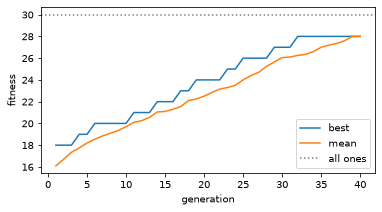

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, GENERATIONS + 1), best, label="best")
ax.plot(range(1, GENERATIONS + 1), mean, label="mean")
ax.axhline(GENOME_LENGTH, color="grey", linestyle=":", label="all ones")
ax.set_xlabel("generation")
ax.set_ylabel("fitness")
ax.legend(loc="lower right")
plt.show()

In [11]:
assert all(b <= a for b, a in itertools.pairwise(best))
assert best[-1] > best[0]

# What was saved

Every individual ever born is in the database: the twenty alive plus each retired one. `size` counts the alive ones; `get_solution` ranks the evaluated alive ones.

In [12]:
print("alive:         ", ea.size)
winner = ea.get_solution("best")
print("best genotype: ", winner.genotype)
print("born in generation", winner.time_of_birth)
ea.close()
assert ea.size == POPULATION_SIZE
assert (DATA / "engine.db").is_file()

alive:          20
best genotype:  [1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
born in generation 32


# Settings

`config` holds the defaults every run falls back on. Each field can be set with an environment variable named `SEACHANGE_` plus the field name (`SEACHANGE_NUM_STEPS=50`). The settings are read-only: pass a value to `EA` instead of changing `config`.

In [13]:
print(config.model_dump(exclude={"db_file_path"}))

{'quiet': False, 'direction': 'max', 'first_generation_id': 0, 'num_steps': 100, 'output_folder': PosixPath('__data__'), 'db_file_name': 'database.db', 'db_handling': 'delete'}


In [14]:
try:
    config.num_steps = 5
except ValidationError as error:
    print(error.errors()[0]["msg"])
print(EASettings(num_steps=5).num_steps)
assert config.num_steps == EASettings().num_steps

Instance is frozen
5
